<a href="https://colab.research.google.com/github/tenzin-selden/YOLO-Object-detection-Practice/blob/main/yolo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
! pip install ultralytics #exclamation marks means telling the colab to run the code as terminal command rather than as python.

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 12.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics]


In [ ]:
from ultralytics.data.utils import check_det_dataset

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [ ]:
data=check_det_dataset("coco128.yaml")


WARNING ⚠️ Dataset 'coco128.yaml' images not found, missing path '/content/datasets/coco128/images/train2017'
Unzipping /content/datasets/coco128.zip to /content/datasets/coco128...: 100% ━━━━━━━━━━━━ 263/263 2.3Kfiles/s 0.1s
Dataset download success ✅ (1.2s), saved to /content/datasets



In [ ]:
print(data.keys())

dict_keys(['path', 'train', 'val', 'test', 'names', 'download', 'yaml_file', 'nc', 'channels'])


In [ ]:
print(data["train"])

/content/datasets/coco128/images/train2017


In [ ]:
print(data["val"])

/content/datasets/coco128/images/train2017


In [ ]:
print(data["names"])

{0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'potted plant', 59: 'bed', 60: 'dining table', 61: 'toilet', 62: 'tv', 63: 'laptop', 64: 'mouse', 65: 'remote', 66: 'keyboard', 67: 'cell phone', 68: 'microw

In [ ]:
import os
dataset_path=os.path.dirname(data["train"])
print(os.listdir(dataset_path))

['train2017']


In [ ]:
import os
train_images=data["train"]
print(train_images)

/content/datasets/coco128/images/train2017


In [ ]:
image_files=os.listdir(train_images)
print("total images:",len(image_files))
print("first image:",image_files[0])

total images: 128
first image: 000000000064.jpg


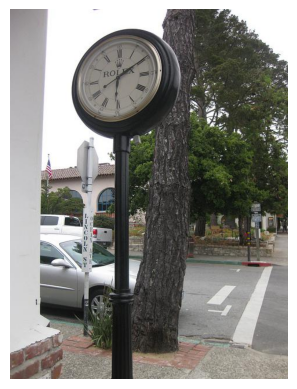

In [ ]:
import cv2
import matplotlib.pyplot as plt
image_path=os.path.join(train_images,image_files[0])
image=cv2.imread(image_path)
image=cv2.cvtColor(image,cv2.COLOR_BGR2RGB)
plt.imshow(image)
plt.axis("off")
plt.show()


In [ ]:
height,width,channels=image.shape
print("height:",height)
print("width:",width)
print("channels:",channels)

height: 640
width: 480
channels: 3


In [ ]:
label_path=image_path.replace(".jpg",".text") #creating the path to the annotation file correspondng to our image
print(label_path)

/content/datasets/coco128/images/train2017/000000000064.text


In [ ]:
label_path=image_path.replace("/images/","/labels/")
label_path=label_path.replace(".jpg",".txt")
print(label_path)


/content/datasets/coco128/labels/train2017/000000000064.txt


In [ ]:
with open(label_path,"r")as file: #read the annotated file -r means read and reads the file linewise and stores in labels
  labels=file.readlines()
print(labels)


['2 0.292792 0.729031 0.367417 0.246281\n', '7 0.239438 0.599242 0.259542 0.0929219\n', '11 0.279896 0.412773 0.077125 0.117453\n', '74 0.394146 0.184914 0.321458 0.237984\n']


In [ ]:
print(labels[0])

2 0.292792 0.729031 0.367417 0.246281



In [ ]:
values=labels[0].split()
class_id=int(values[0]) #xcenter=xleft+xright/2  ycenter=ytop+ybottom/2  ans u get in each will be divided by their respective image dimension. eg:200/640 and 150/427
x_center=float(values[1])
y_center=float(values[2])
box_width=float(values[3])
box_height=float(values[4])
print(class_id)
print(x_center,y_center)
print(box_width,box_height)

2
0.292792 0.729031
0.367417 0.246281


In [ ]:
height,width,channels=image.shape
x_center=x_center*width
y_center=y_center*height
print(x_center,y_center)

140.54016 466.57984


In [ ]:
box_width=box_width*width
box_height=box_height*height
print(box_width,box_height)

176.36016 157.61984


In [ ]:
xc=float(values[1])*width #calculating the four corners of bounding box
yc=float(values[2])*height
bw=float(values[3])*width
bh=float(values[4])*height
left=int(xc-bw/2)
right=int(xc+bw/2)
top=int(yc-bh/2)
bottom=int(yc+bh/2)
print(left,right,top,bottom)


52 228 387 545


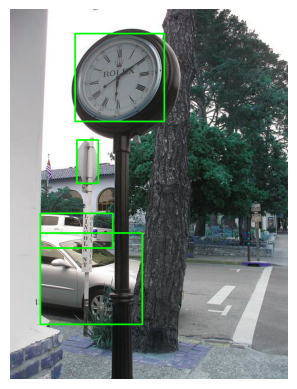

In [ ]:
image_copy=image.copy()
height,width=image.shape[:2]
for label in labels:
  values=label.split()
  class_id=int(values[0])
  x_center=float(values[1])
  y_center=float(values[2])
  box_width=float(values[3])
  box_height=float(values[4])
  x_center*=width
  y_center*=height
  box_width*=width
  box_height*=height
  left=int(x_center-box_width/2)
  top=int(y_center-box_height/2)
  right=int(x_center+box_width/2)
  bottom=int(y_center+box_height/2)
  cv2.rectangle(
      image_copy,(left,top),(right,bottom),(0,255,0),2
  )
plt.imshow(cv2.cvtColor(image_copy,cv2.COLOR_BGR2RGB))
plt.axis("Off")
plt.show()



In [ ]:
print(labels)

['2 0.292792 0.729031 0.367417 0.246281\n', '7 0.239438 0.599242 0.259542 0.0929219\n', '11 0.279896 0.412773 0.077125 0.117453\n', '74 0.394146 0.184914 0.321458 0.237984\n']


In [ ]:
for label in labels:
  class_id=int(label[0])
  print(class_id)

2
7
1
7


In [ ]:
class_names=[
    "person", "bicycle", "car", "motorcycle", "airplane",
    "bus", "train", "truck", "boat", "traffic light",
    "fire hydrant", "stop sign", "parking meter", "bench", "bird",
    "cat", "dog", "horse", "sheep", "cow",
    "elephant", "bear", "zebra", "giraffe", "backpack",
    "umbrella", "handbag", "tie", "suitcase", "frisbee",
    "skis", "snowboard", "sports ball", "kite", "baseball bat",
    "baseball glove", "skateboard", "surfboard", "tennis racket", "bottle",
    "wine glass", "cup", "fork", "knife", "spoon",
    "bowl", "banana", "apple", "sandwich", "orange",
    "broccoli", "carrot", "hot dog", "pizza", "donut",
    "cake", "chair", "couch", "potted plant", "bed",
    "dining table", "toilet", "tv", "laptop", "mouse",
    "remote", "keyboard", "cell phone", "microwave", "oven",
    "toaster", "sink", "refrigerator", "book", "clock",
    "vase", "scissors", "teddy bear", "hair drier", "toothbrush"
]



In [ ]:
for label in labels:
  class_id=int(label[0])
  class_name=class_names[class_id]
  print(class_name)

car
truck
bicycle
truck


In [ ]:

for i, label in enumerate(labels): #enumerate means counting one by one
    print(i, repr(label)) #repr helps in showing it in detail


0 '2 0.292792 0.729031 0.367417 0.246281\n'
1 '7 0.239438 0.599242 0.259542 0.0929219\n'
2 '11 0.279896 0.412773 0.077125 0.117453\n'
3 '74 0.394146 0.184914 0.321458 0.237984\n'


In [ ]:
for label in labels:
  values=label.split()
  print(values)

['2', '0.292792', '0.729031', '0.367417', '0.246281']
['7', '0.239438', '0.599242', '0.259542', '0.0929219']
['11', '0.279896', '0.412773', '0.077125', '0.117453']
['74', '0.394146', '0.184914', '0.321458', '0.237984']


In [ ]:
image_copy = image.copy()

height, width = image.shape[:2]


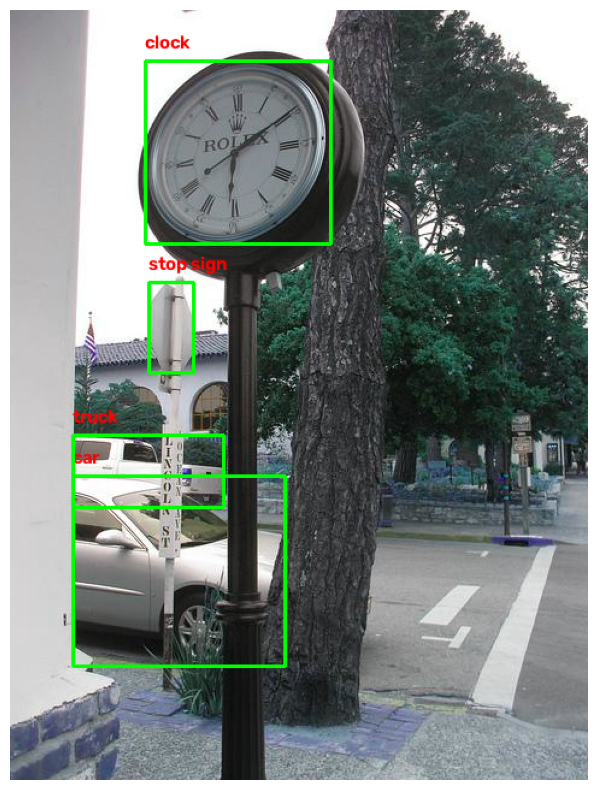

In [ ]:
for label in labels:

    # Separate the five values
    values = label.split()

    # Extract class ID and class name
    class_id = int(values[0])
    class_name = class_names[class_id]

    # Extract coordinates
    x_center = float(values[1]) * width
    y_center = float(values[2]) * height
    box_width = float(values[3]) * width
    box_height = float(values[4]) * height

    # Calculate box corners
    left = int(x_center - box_width / 2)
    top = int(y_center - box_height / 2)
    right = int(x_center + box_width / 2)
    bottom = int(y_center + box_height / 2)

    # Draw bounding box
    cv2.rectangle(
        image_copy,
        (left, top),
        (right, bottom),
        (0, 255, 0),
        2
    )

    # Write class name
    cv2.putText(
        image_copy,
        class_name,
        (left, max(top - 10, 15)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (0, 0, 255),
        2
    )

plt.figure(figsize=(14, 10))
plt.imshow(cv2.cvtColor(image_copy, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

In [ ]:
import os
print(os.listdir('/content'))

['.config', 'datasets', 'sample_data']


In [ ]:
print(os.listdir('/content/datasets'))

['coco128']


In [ ]:
print(os.listdir('/content/datasets/coco128'))

['README.txt', 'images', 'LICENSE', 'labels']


In [ ]:
print(os.listdir('/content/datasets/coco128/images'))

['train2017']


In [ ]:
image_folder='/content/datasets/coco128/images/train2017'
import os
images=os.listdir(image_folder)
print("total images=",len(images))
print("the first five images=",images[:5])



total images= 128
the first five images= ['000000000064.jpg', '000000000034.jpg', '000000000260.jpg', '000000000061.jpg', '000000000308.jpg']


In [ ]:
import os
label_folder='/content/datasets/coco128/labels/train2017'
labels=os.listdir(label_folder)
print("total label file=",len(labels))
print("first five labels=",labels[:5])



total label file= 128
first five labels= ['000000000143.txt', '000000000074.txt', '000000000486.txt', '000000000597.txt', '000000000025.txt']


In [ ]:
import os
matched=0
missing=0
for image_name in images:
  name=os.path.splitext(image_name)[0]
  label_name=name+".txt"
  label_path=os.path.join(label_folder,label_name)
  if os.path.exists(label_path):
    matched+=1
  else:
    missing+=1
print("matching image-label pairs=",matched)
print("images without the labels=",missing )

matching image-label pairs= 126
images without the labels= 2


In [ ]:
for image_name in images:
  name=os.path.splitext(image_name)[0]
  label_name=name+".txt"
  label_path=os.path.join(label_folder,label_name)
  if not os.path.exists(label_path):
    print("missing label for=",image_name)

missing label for= 000000000508.jpg
missing label for= 000000000250.jpg


In [ ]:
import os
output_folder='/content/annotated_images'
os.makedirs(output_folder,exist_ok=True)
print('ouput folder created successfully')

ouput folder created successfully


In [ ]:

import cv2
import os
image_name=images[0]
image_path=os.path.join(image_folder,image_name)
name=os.path.splitext(image_name)[0]
label_name=name+".txt"
label_path=os.path.join(label_folder,label_name)
image=cv2.imread(image_path)
with open(label_path,"r")as file:
  annotation_lines=file.readlines()
print("image and label loaded successfully")



image and label loaded successfully


In [ ]:
image_copy=image.copy()
height,width=image.shape[:2]
for label in annotation_lines:

    # Separate the five values
    values = label.strip().split()

    # Extract class ID and class name
    class_id = int(values[0])
    class_name = class_names[class_id]

    # Extract coordinates
    x_center = float(values[1]) * width
    y_center = float(values[2]) * height
    box_width = float(values[3]) * width
    box_height = float(values[4]) * height

    # Calculate box corners
    left = int(x_center - box_width / 2)
    top = int(y_center - box_height / 2)
    right = int(x_center + box_width / 2)
    bottom = int(y_center + box_height / 2)

    # Draw bounding box
    cv2.rectangle(
        image_copy,
        (left, top),
        (right, bottom),
        (0, 255, 0),
        2
    )
    cv2.putText(
        image_copy,
        class_name,
        (left, max(top - 10, 15)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (0, 0, 255),
        2
    )

In [ ]:
output_path=os.path.join(output_folder,image_name)
cv2.imwrite(output_path,image_copy)
print("annotated iamge saved sucessfully")

annotated iamge saved sucessfully


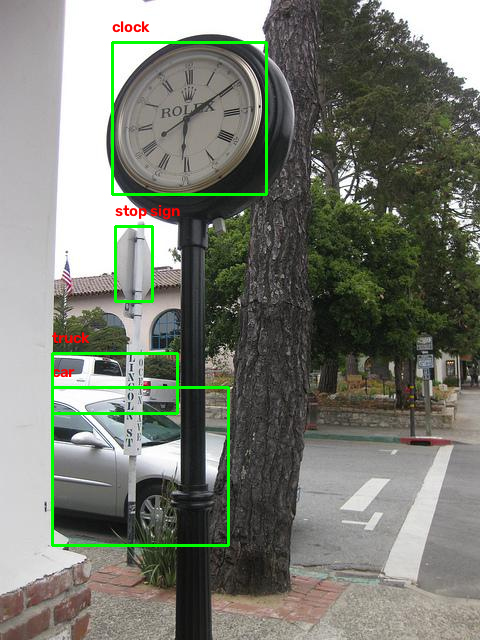

In [ ]:
from google.colab.patches import cv2_imshow
cv2_imshow(image_copy)

In [ ]:
import os
import cv2


processed = 0
skipped = 0

# Visit every image in the image folder
for image_name in images:

    # Create the image path
    image_path = os.path.join(image_folder, image_name)

    # Remove the image extension
    name = os.path.splitext(image_name)[0]

    # Find the matching annotation file
    label_name = name + '.txt'
    label_path = os.path.join(label_folder, label_name)

    # Skip images without annotation files
    if not os.path.exists(label_path):
        skipped += 1
        continue

    # Read the image
    image = cv2.imread(image_path)

    if image is None:
        skipped += 1
        continue

    # Read the annotation file
    with open(label_path, 'r') as file:
        annotation_lines = file.readlines()

    # Make a copy of the original image
    image_copy = image.copy()

    # Get image dimensions
    height, width = image.shape[:2]

    # Process every object in the annotation file
    for label in annotation_lines:

        values = label.strip().split()

        class_id = int(values[0])
        class_name = class_names[class_id]

        x_center = float(values[1]) * width
        y_center = float(values[2]) * height

        box_width = float(values[3]) * width
        box_height = float(values[4]) * height

        left = int(x_center - box_width / 2)
        top = int(y_center - box_height / 2)

        right = int(x_center + box_width / 2)
        bottom = int(y_center + box_height / 2)

        cv2.rectangle(
            image_copy,
            (left, top),
            (right, bottom),
            (0, 255, 0),
            2
        )

        cv2.putText(
            image_copy,
            class_name,
            (left, max(top - 10, 15)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (0, 0, 255),
            2
        )

    # Save the annotated image
    output_path = os.path.join(output_folder, image_name)

    success = cv2.imwrite(output_path, image_copy)

    if success:
        processed += 1
    else:
        skipped += 1

print("Processing completed!")
print("Images successfully processed:", processed)
print("Images skipped:", skipped)

Processing completed!
Images successfully processed: 126
Images skipped: 2


image: 000000000064.jpg


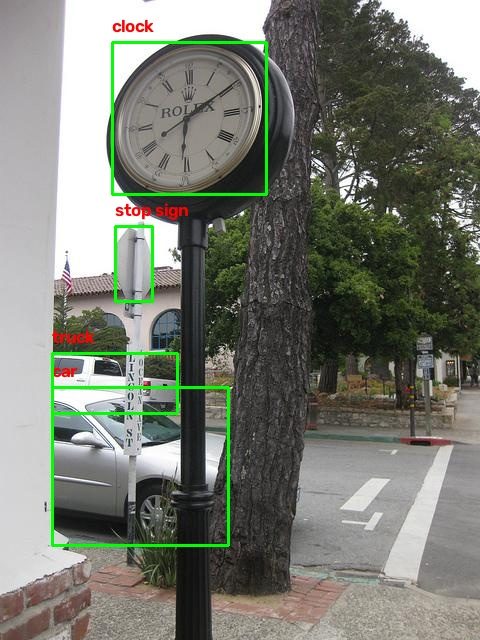

image: 000000000034.jpg


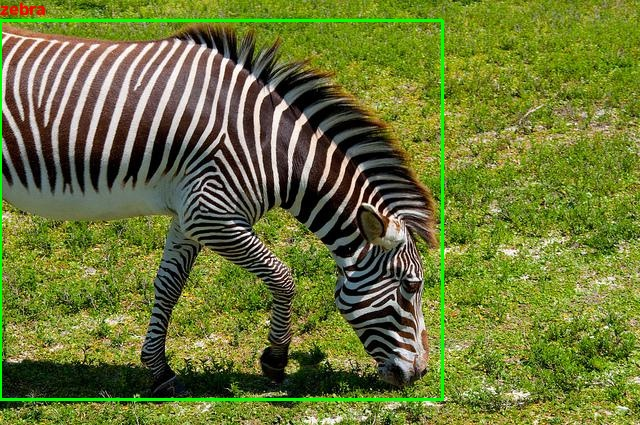

image: 000000000260.jpg


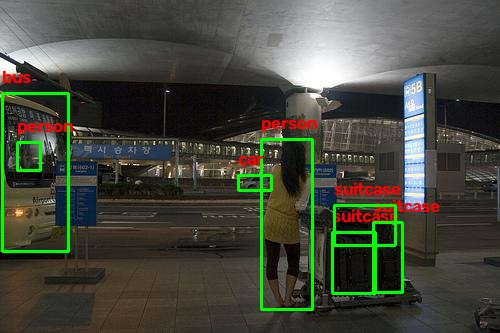

image: 000000000061.jpg


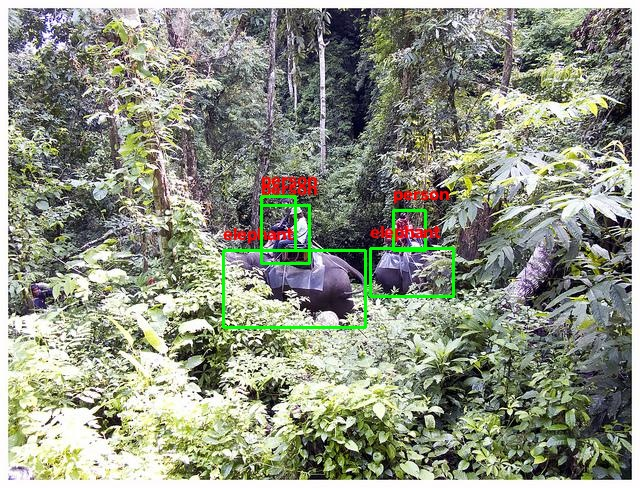

image: 000000000308.jpg


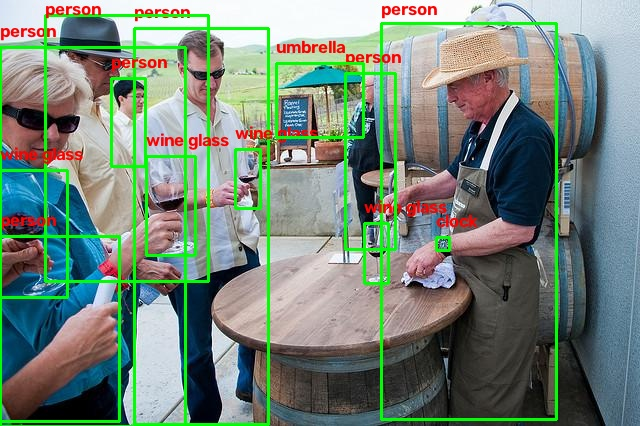

In [ ]:
saved_images=os.listdir(output_folder)
for image_name in saved_images[:5]:
  image_path=os.path.join(output_folder,image_name)
  image=cv2.imread(image_path)
  print("image:",image_name)
  cv2_imshow(image)



In [ ]:
import ultralytics
import os
package_folder=os.path.dirname(ultralytics.__file__)
yaml_path=os.path.join(package_folder,'cfg','datasets','coco128.yaml')
print("yaml location=",yaml_path)
print("does the file exists:",os.path.exists(yaml_path))

yaml location= /usr/local/lib/python3.13/dist-packages/ultralytics/cfg/datasets/coco128.yaml
does the file exists: True


reading the original yaml file

In [ ]:
with open(yaml_path,"r")as file:
  yaml_content=file.read()
print(yaml_content)

# Ultralytics 🚀 AGPL-3.0 License - https://ultralytics.com/license

# COCO128 dataset https://www.kaggle.com/datasets/ultralytics/coco128 (first 128 images from COCO train2017) by Ultralytics
# Documentation: https://docs.ultralytics.com/datasets/detect/coco128
# Example usage: yolo train data=coco128.yaml
# parent
# ├── ultralytics
# └── datasets
#     └── coco128 ← downloads here (7 MB)

# Train/val/test sets as 1) dir: path/to/imgs, 2) file: path/to/imgs.txt, or 3) list: [path/to/imgs1, path/to/imgs2, ..]
path: coco128 # dataset root dir
train: images/train2017 # train images (relative to 'path') 128 images
val: images/train2017 # val images (relative to 'path') 128 images
test: # test images (optional)

# Classes
names:
  0: person
  1: bicycle
  2: car
  3: motorcycle
  4: airplane
  5: bus
  6: train
  7: truck
  8: boat
  9: traffic light
  10: fire hydrant
  11: stop sign
  12: parking meter
  13: bench
  14: bird
  15: cat
  16: dog
  17: horse
  18: sheep
  19: cow
  20: elep

creating our own yaml file(dataset configuration so that it becomes easier for yolo to locate the files path)

In [ ]:
%%writefile /content/my_coco128.yaml
path: /content/datasets/coco128
train: images/train2017
val: images/train2017
names:
  0: person
  1: bicycle
  2: car
  3: motorcycle
  4: airplane
  5: bus
  6: train
  7: truck
  8: boat
  9: traffic light
  10: fire hydrant
  11: stop sign
  12: parking meter
  13: bench
  14: bird
  15: cat
  16: dog
  17: horse
  18: sheep
  19: cow
  20: elephant
  21: bear
  22: zebra
  23: giraffe
  24: backpack
  25: umbrella
  26: handbag
  27: tie
  28: suitcase
  29: frisbee
  30: skis
  31: snowboard
  32: sports ball
  33: kite
  34: baseball bat
  35: baseball glove
  36: skateboard
  37: surfboard
  38: tennis racket
  39: bottle
  40: wine glass
  41: cup
  42: fork
  43: knife
  44: spoon
  45: bowl
  46: banana
  47: apple
  48: sandwich
  49: orange
  50: broccoli
  51: carrot
  52: hot dog
  53: pizza
  54: donut
  55: cake
  56: chair
  57: couch
  58: potted plant
  59: bed
  60: dining table
  61: toilet
  62: tv
  63: laptop
  64: mouse
  65: remote
  66: keyboard
  67: cell phone
  68: microwave
  69: oven
  70: toaster
  71: sink
  72: refrigerator
  73: book
  74: clock
  75: vase
  76: scissors
  77: teddy bear
  78: hair drier
  79: toothbrush

Writing /content/my_coco128.yaml


In [ ]:
with open('/content/my_coco128.yaml','r') as file:
  content=file.read()
print(content)


path: /content/datasets/coco128
train: images/train2017
val: images/train2017
names:
  0: person
  1: bicycle
  2: car
  3: motorcycle
  4: airplane
  5: bus
  6: train
  7: truck
  8: boat
  9: traffic light
  10: fire hydrant
  11: stop sign
  12: parking meter
  13: bench
  14: bird
  15: cat
  16: dog
  17: horse
  18: sheep
  19: cow
  20: elephant
  21: bear
  22: zebra
  23: giraffe
  24: backpack
  25: umbrella
  26: handbag
  27: tie
  28: suitcase
  29: frisbee
  30: skis
  31: snowboard
  32: sports ball
  33: kite
  34: baseball bat
  35: baseball glove
  36: skateboard
  37: surfboard
  38: tennis racket
  39: bottle
  40: wine glass
  41: cup
  42: fork
  43: knife
  44: spoon
  45: bowl
  46: banana
  47: apple
  48: sandwich
  49: orange
  50: broccoli
  51: carrot
  52: hot dog
  53: pizza
  54: donut
  55: cake
  56: chair
  57: couch
  58: potted plant
  59: bed
  60: dining table
  61: toilet
  62: tv
  63: laptop
  64: mouse
  65: remote
  66: keyboard
  67: cell p

In [ ]:
from ultralytics.data.utils import check_det_dataset

In [ ]:
data=check_det_dataset('/content/my_coco128.yaml')
print(data.keys())

dict_keys(['path', 'train', 'val', 'names', 'yaml_file', 'nc', 'channels'])


In [ ]:
print(data['nc'])

80


In [ ]:
print("training iamges;",data['train'])
print("validation images:",data['val'])

training iamges; /content/datasets/coco128/images/train2017
validation images: /content/datasets/coco128/images/train2017


In [ ]:
from ultralytics import YOLO

In [ ]:
model=YOLO("yolov8n.pt")

In [ ]:
results=model.train(
    data='/content/my_coco128.yaml',
    epochs=10,
    imgsz=640
)



Ultralytics 8.4.214 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (AMD EPYC 7B12)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/my_coco128.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/runs/detect/train/weights/best.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-2, nbs=64, nms=None, opset=None, opt

In [ ]:
metrics=model.val()

Ultralytics 8.4.214 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (AMD EPYC 7B12)
Model summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2201.5±868.7 MB/s, size: 44.1 KB)
val: Scanning /content/datasets/coco128/labels/train2017.cache... 126 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 44.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 1.9s/it 15.4s
                   all        128        929      0.741      0.752      0.788      0.604
                person         61        254      0.867      0.724      0.809      0.589
               bicycle          3          6      0.691      0.382      0.514      0.463
                   car         12         46      0.642      0.391      0.483      0.261
            motorcycle          4          5      0.807      0.842      0.962      0.855
              airplane          5          6  

In [ ]:
print(metrics.results_dict)

{'metrics/precision(B)': 0.7412339326737634, 'metrics/recall(B)': 0.751548621269123, 'metrics/mAP50(B)': 0.7880761148942615, 'metrics/mAP50-95(B)': 0.60442817224333, 'fitness': 0.60442817224333}


In [ ]:
results=model.predict( #this time yolo is just looking at the raw image and then making its prediction
    source='/content/datasets/coco128/images/train2017',
    save=True
)


image 1/128 /content/datasets/coco128/images/train2017/000000000009.jpg: 480x640 3 bowls, 6 oranges, 1 broccoli, 110.9ms
image 2/128 /content/datasets/coco128/images/train2017/000000000025.jpg: 448x640 2 giraffes, 103.7ms
image 3/128 /content/datasets/coco128/images/train2017/000000000030.jpg: 448x640 1 potted plant, 1 vase, 96.3ms
image 4/128 /content/datasets/coco128/images/train2017/000000000034.jpg: 448x640 1 zebra, 95.7ms
image 5/128 /content/datasets/coco128/images/train2017/000000000036.jpg: 640x512 1 person, 1 umbrella, 114.7ms
image 6/128 /content/datasets/coco128/images/train2017/000000000042.jpg: 480x640 1 dog, 1 couch, 97.8ms
image 7/128 /content/datasets/coco128/images/train2017/000000000049.jpg: 640x512 8 persons, 2 horses, 1 potted plant, 104.3ms
image 8/128 /content/datasets/coco128/images/train2017/000000000061.jpg: 512x640 2 persons, 2 elephants, 118.4ms
image 9/128 /content/datasets/coco128/images/train2017/000000000064.jpg: 640x480 1 car, 1 truck, 1 stop sign, 1 cl

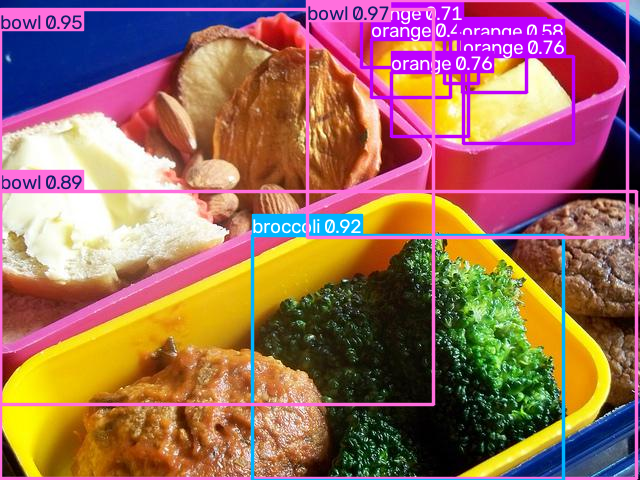

In [ ]:
from PIL import Image
from IPython.display import display
display(Image.fromarray(results[0].plot()[:,:,::-1]))

In [ ]:
results=model.predict(
    source='/content/datasets/coco128/images/train2017',
    conf=0.5,
    save=True
)


image 1/128 /content/datasets/coco128/images/train2017/000000000009.jpg: 480x640 3 bowls, 4 oranges, 1 broccoli, 102.0ms
image 2/128 /content/datasets/coco128/images/train2017/000000000025.jpg: 448x640 2 giraffes, 96.1ms
image 3/128 /content/datasets/coco128/images/train2017/000000000030.jpg: 448x640 1 potted plant, 1 vase, 92.1ms
image 4/128 /content/datasets/coco128/images/train2017/000000000034.jpg: 448x640 1 zebra, 96.9ms
image 5/128 /content/datasets/coco128/images/train2017/000000000036.jpg: 640x512 1 person, 1 umbrella, 104.4ms
image 6/128 /content/datasets/coco128/images/train2017/000000000042.jpg: 480x640 1 dog, 100.6ms
image 7/128 /content/datasets/coco128/images/train2017/000000000049.jpg: 640x512 6 persons, 2 horses, 1 potted plant, 104.1ms
image 8/128 /content/datasets/coco128/images/train2017/000000000061.jpg: 512x640 1 person, 1 elephant, 105.0ms
image 9/128 /content/datasets/coco128/images/train2017/000000000064.jpg: 640x480 1 car, 1 truck, 1 stop sign, 1 clock, 98.8ms

In [ ]:
for box in results[0].boxes:
  class_id=int(box.cls[0])
  confidence=float(box.conf[0])
  print(model.names[class_id],round(confidence,2))

bowl 0.97
bowl 0.95
broccoli 0.92
bowl 0.89
orange 0.76
orange 0.76
orange 0.71
orange 0.58


In [ ]:
for box in results[0].boxes:
  print(box.xyxy)

tensor([[307.3084,   0.0000, 627.4927, 237.6557]])
tensor([[  0.0000,   9.6093, 433.7253, 404.5910]])
tensor([[252.9681, 235.8193, 563.3743, 480.0000]])
tensor([[  0.0000, 191.0555, 636.9985, 478.7115]])
tensor([[391.6557,  72.0669, 468.9732, 136.6506]])
tensor([[463.8173,  56.7603, 573.3028, 143.4511]])
tensor([[361.1009,   0.0000, 458.4865,  67.7840]])
tensor([[462.6680,  40.5599, 526.9564,  92.0081]])


In [ ]:
for box in results[0].boxes:
  class_id=int(box.cls[0])
  confidence=float(box.conf[0])
  coordinates=box.xyxy[0].tolist()

  print("object:",model.names[class_id])
  print("confidence:",round(confidence,2))
  print("coordinates:",coordinates)
  print("-------------")


object: bowl
confidence: 0.97
coordinates: [307.30841064453125, 0.0, 627.49267578125, 237.65574645996094]
-------------
object: bowl
confidence: 0.95
coordinates: [0.0, 9.609283447265625, 433.72528076171875, 404.59100341796875]
-------------
object: broccoli
confidence: 0.92
coordinates: [252.9681396484375, 235.8192901611328, 563.374267578125, 480.0]
-------------
object: bowl
confidence: 0.89
coordinates: [0.0, 191.0555419921875, 636.9984741210938, 478.71148681640625]
-------------
object: orange
confidence: 0.76
coordinates: [391.65570068359375, 72.06690979003906, 468.97320556640625, 136.65060424804688]
-------------
object: orange
confidence: 0.76
coordinates: [463.81732177734375, 56.76026916503906, 573.3027954101562, 143.45108032226562]
-------------
object: orange
confidence: 0.71
coordinates: [361.1008605957031, 0.0, 458.4865417480469, 67.78397369384766]
-------------
object: orange
confidence: 0.58
coordinates: [462.66802978515625, 40.55992126464844, 526.9563598632812, 92.008117

In [ ]:
print(model.trainer.best)

/content/runs/detect/train-2/weights/best.pt


helps us view the learned parameters  of the network.

In [ ]:
weights=model.model.state_dict()
print(weights.keys())

odict_keys(['model.0.conv.weight', 'model.0.bn.weight', 'model.0.bn.bias', 'model.0.bn.running_mean', 'model.0.bn.running_var', 'model.0.bn.num_batches_tracked', 'model.1.conv.weight', 'model.1.bn.weight', 'model.1.bn.bias', 'model.1.bn.running_mean', 'model.1.bn.running_var', 'model.1.bn.num_batches_tracked', 'model.2.cv1.conv.weight', 'model.2.cv1.bn.weight', 'model.2.cv1.bn.bias', 'model.2.cv1.bn.running_mean', 'model.2.cv1.bn.running_var', 'model.2.cv1.bn.num_batches_tracked', 'model.2.cv2.conv.weight', 'model.2.cv2.bn.weight', 'model.2.cv2.bn.bias', 'model.2.cv2.bn.running_mean', 'model.2.cv2.bn.running_var', 'model.2.cv2.bn.num_batches_tracked', 'model.2.m.0.cv1.conv.weight', 'model.2.m.0.cv1.bn.weight', 'model.2.m.0.cv1.bn.bias', 'model.2.m.0.cv1.bn.running_mean', 'model.2.m.0.cv1.bn.running_var', 'model.2.m.0.cv1.bn.num_batches_tracked', 'model.2.m.0.cv2.conv.weight', 'model.2.m.0.cv2.bn.weight', 'model.2.m.0.cv2.bn.bias', 'model.2.m.0.cv2.bn.running_mean', 'model.2.m.0.cv2.bn.

In [ ]:
first_weight=next(iter(weights.values())) #displays actual numerical values from one of the model's layers
print(first_weight)

tensor([[[[-1.1548e-01, -1.0803e-02,  1.0669e-01],
          [-3.6841e-01,  3.3325e-02,  3.8721e-01],
          [-3.3740e-01, -1.3802e-02,  3.1177e-01]],

         [[-1.4246e-01,  9.6970e-03,  1.5210e-01],
          [-4.8999e-01,  2.7924e-02,  4.6021e-01],
          [-3.7256e-01, -2.7199e-03,  3.4814e-01]],

         [[-4.9988e-02, -1.5053e-02,  2.4750e-02],
          [-2.1375e-01,  3.2867e-02,  1.9385e-01],
          [-1.5356e-01,  3.1067e-02,  1.5649e-01]]],


        [[[ 1.2627e-02,  1.9257e-02,  8.0109e-03],
          [-2.0065e-03, -2.3102e-02,  3.2387e-03],
          [-1.6251e-02, -1.4038e-01, -1.7395e-02]],

         [[-9.4070e-03,  1.2207e-02,  3.8767e-04],
          [-7.0572e-03, -2.6367e-02, -6.0196e-03],
          [-2.0432e-02, -1.3989e-01, -2.2858e-02]],

         [[-2.1286e-03,  3.9597e-03, -4.5357e-03],
          [ 3.1929e-03, -8.4763e-03,  5.4588e-03],
          [ 1.0017e-02, -6.1493e-02,  1.7365e-02]]],


        [[[-1.0040e-02, -8.2214e-02, -3.0487e-02],
          [-1.2

In [ ]:
best_model=YOLO(model.trainer.best)

In [ ]:
best_metrics=best_model.val(
    data='/content/my_coco128.yaml'
    )

Ultralytics 8.4.214 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (AMD EPYC 7B12)
Model summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1776.7±1101.1 MB/s, size: 69.2 KB)
val: Scanning /content/datasets/coco128/labels/train2017.cache... 126 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 2.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 1.9s/it 15.4s
                   all        128        929      0.741      0.752      0.788      0.604
                person         61        254      0.867      0.724      0.809      0.589
               bicycle          3          6      0.691      0.382      0.514      0.463
                   car         12         46      0.642      0.391      0.483      0.261
            motorcycle          4          5      0.807      0.842      0.962      0.855
              airplane          5          6  

In [ ]:
print(best_metrics.results_dict)

{'metrics/precision(B)': 0.7412339326737634, 'metrics/recall(B)': 0.751548621269123, 'metrics/mAP50(B)': 0.7880761148942615, 'metrics/mAP50-95(B)': 0.60442817224333, 'fitness': 0.60442817224333}


In [ ]:
print(best_metrics.save_dir)

/content/runs/detect/val-3


In [ ]:
best_metrics=best_model.val(
    data='/content/my_coco128.yaml',
    plots=True
)

Ultralytics 8.4.214 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (AMD EPYC 7B12)
Model summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2486.7±1274.0 MB/s, size: 71.4 KB)
val: Scanning /content/datasets/coco128/labels/train2017.cache... 126 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 41.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 1.9s/it 15.1s
                   all        128        929      0.741      0.752      0.788      0.604
                person         61        254      0.867      0.724      0.809      0.589
               bicycle          3          6      0.691      0.382      0.514      0.463
                   car         12         46      0.642      0.391      0.483      0.261
            motorcycle          4          5      0.807      0.842      0.962      0.855
              airplane          5          6 

In [ ]:
from IPython.display import Image,display
import os
print(os.listdir(best_metrics.save_dir))

['val_batch0_pred.jpg', 'val_batch2_pred.jpg', 'val_batch1_labels.jpg', 'val_batch2_labels.jpg', 'BoxR_curve.png', 'BoxF1_curve.png', 'BoxP_curve.png', 'val_batch0_labels.jpg', 'val_batch1_pred.jpg', 'confusion_matrix_normalized.png', 'BoxPR_curve.png', 'confusion_matrix.png']


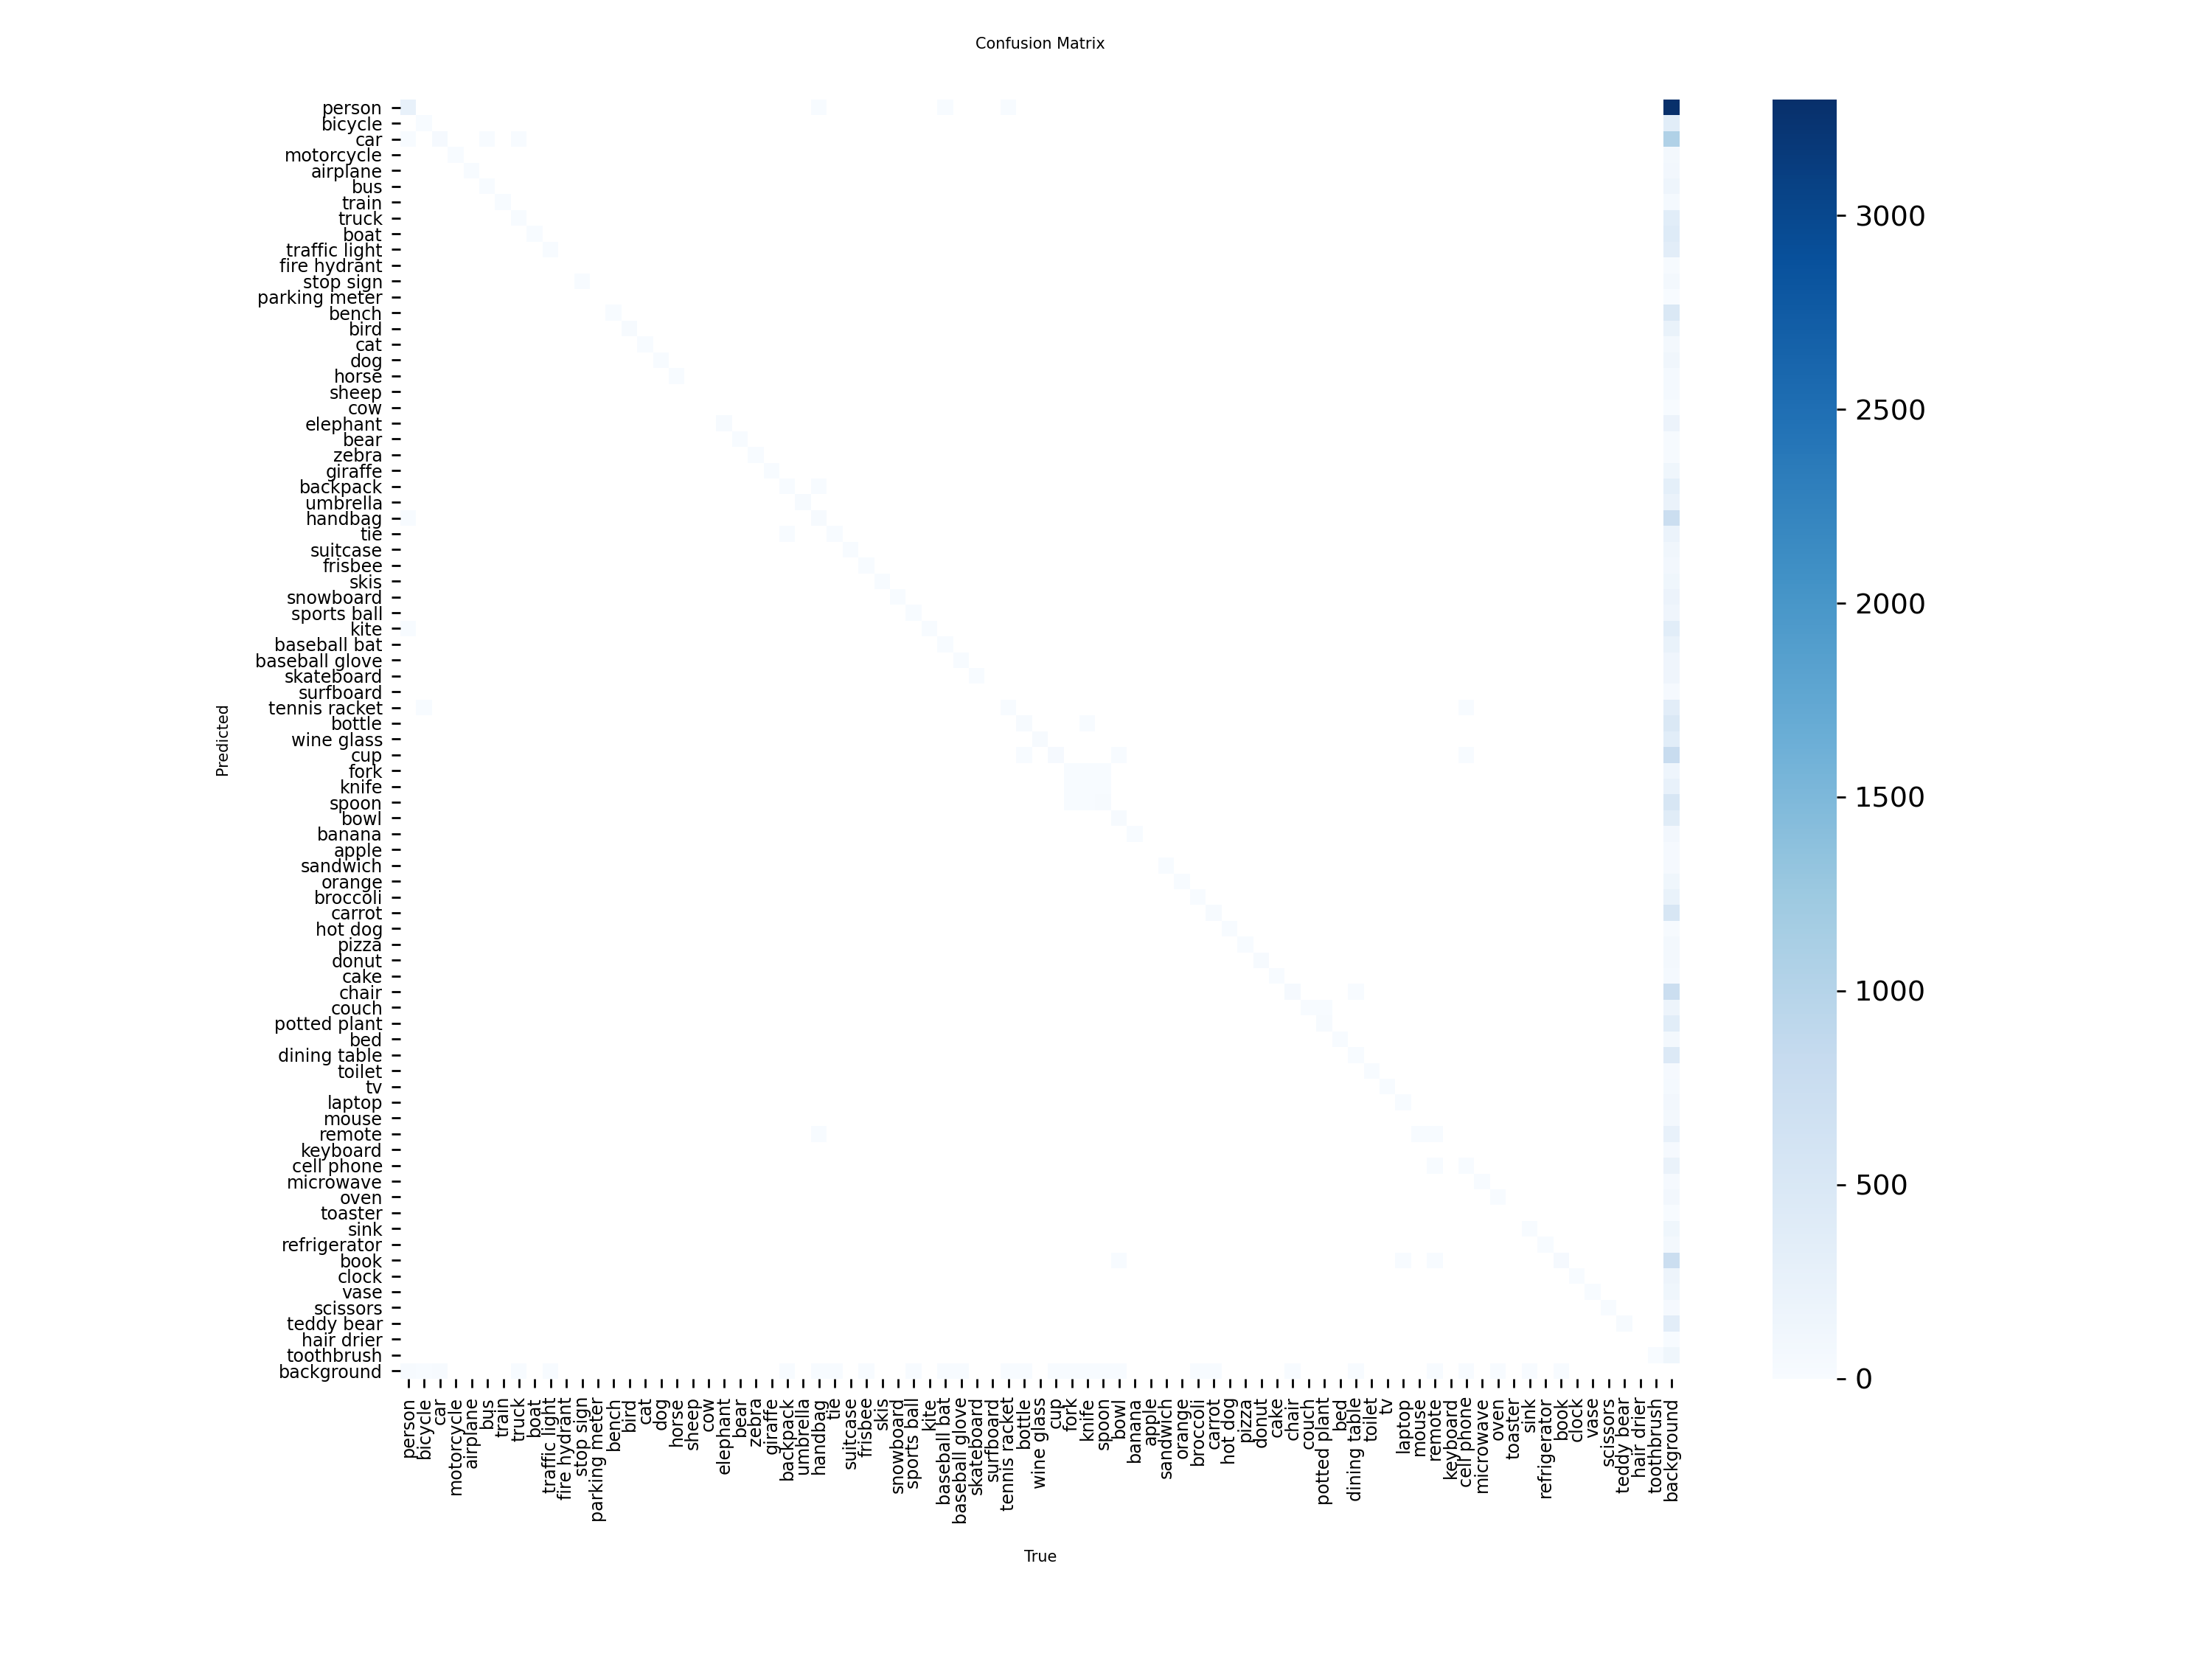

In [ ]:
display(Image(filename=str(best_metrics.save_dir/'confusion_matrix.png')))

In [ ]:
predictions=best_model.predict(
    source='/content/datasets/coco128/images/train2017',
    save=True
)


image 1/128 /content/datasets/coco128/images/train2017/000000000009.jpg: 480x640 3 bowls, 6 oranges, 1 broccoli, 253.4ms
image 2/128 /content/datasets/coco128/images/train2017/000000000025.jpg: 448x640 2 giraffes, 122.1ms
image 3/128 /content/datasets/coco128/images/train2017/000000000030.jpg: 448x640 1 potted plant, 1 vase, 185.8ms
image 4/128 /content/datasets/coco128/images/train2017/000000000034.jpg: 448x640 1 zebra, 131.8ms
image 5/128 /content/datasets/coco128/images/train2017/000000000036.jpg: 640x512 1 person, 1 umbrella, 356.2ms
image 6/128 /content/datasets/coco128/images/train2017/000000000042.jpg: 480x640 1 dog, 1 couch, 119.5ms
image 7/128 /content/datasets/coco128/images/train2017/000000000049.jpg: 640x512 8 persons, 2 horses, 1 potted plant, 103.0ms
image 8/128 /content/datasets/coco128/images/train2017/000000000061.jpg: 512x640 2 persons, 2 elephants, 114.9ms
image 9/128 /content/datasets/coco128/images/train2017/000000000064.jpg: 640x480 1 car, 1 truck, 1 stop sign, 1

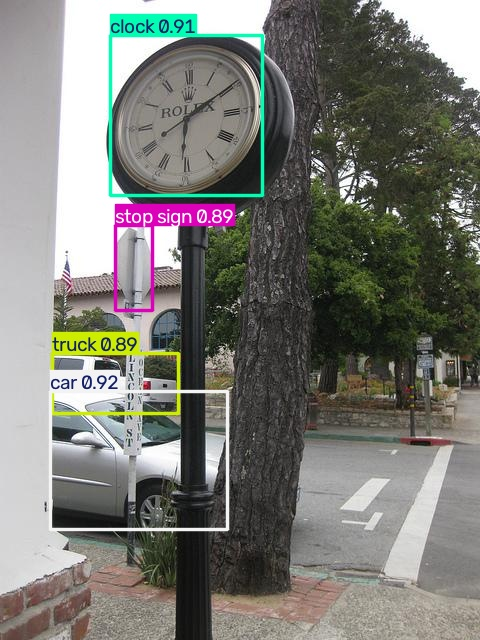

In [ ]:
import glob
image_path=glob.glob('/content/runs/detect/predict-2/*.jpg')[0]
display(Image(filename=image_path))